# Effect of varying threshold for self-training: sklearn vs Moxie

**Reference example:** `../scikit-learn/examples/semi_supervised/plot_self_training_varying_threshold.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/semi_supervised/plot_self_training_varying_threshold.html)).

**Scenario:** breast-cancer data with 50 of 569 labels. A `SelfTrainingClassifier` is fitted under 3-fold
`StratifiedKFold` for 14 thresholds; the example plots accuracy, the number of labeled samples
(from `labeled_iter_`) and the last labeling iteration.

**Adaptations:**
- **Base estimator:** the example uses `CalibratedClassifierCV(SVC(gamma=0.001, random_state=42))`. Moxie has no
  calibration adapter for its `SVC` (`CalibrationEstimator`, calibration tracking PR #11 part 1) and no
  self-training adapter for `CalibratedClassifierCV`, so both sides use `GaussianNB()` here, through the
  family's `GaussianNBAdapter`. The sklearn reference is rerun with `GaussianNB()` so the comparison is like for like.
  The original SVC run is shown as a GAP.
- The folds come from sklearn's `StratifiedKFold` in Python and are shared as index arrays; Mojo slices the rows.
- Extra: `criterion="k_best"` (k_best=10, `max_iter=None`) on the same folds, with `termination_condition_`,
  `n_iter_`, `transduction_` and `predict_proba` compared.

**Determinism:** deterministic (fixed shuffle seed, unshuffled folds, closed-form GaussianNB), so
`labeled_iter_`, iteration counts and predictions are compared exactly.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("semi_supervised/plot_self_training_varying_threshold")

## 1. scikit-learn (Python reference)

The official loop, with `GaussianNB()` substituted for the calibrated SVC.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn import datasets
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.utils import shuffle

n_splits = 3

X, y = datasets.load_breast_cancer(return_X_y=True)
X, y = shuffle(X, y, random_state=42)
y_true = y.copy()
y[50:] = -1
total_samples = y.shape[0]

base_classifier = GaussianNB()  # adapted: CalibratedClassifierCV(SVC(gamma=0.001, random_state=42))

x_values = np.arange(0.4, 1.05, 0.05)
x_values = np.append(x_values, 0.99999)
scores = np.empty((x_values.shape[0], n_splits))
amount_labeled = np.empty((x_values.shape[0], n_splits))
amount_iterations = np.empty((x_values.shape[0], n_splits))

sk_labeled_iter, sk_pred, sk_n_iter, sk_term = [], [], [], []
folds = list(StratifiedKFold(n_splits=n_splits).split(X, y))
for i, threshold in enumerate(x_values):
    self_training_clf = SelfTrainingClassifier(base_classifier, threshold=threshold)

    # We need manual cross validation so that we don't treat -1 as a separate
    # class when computing accuracy
    for fold, (train_index, test_index) in enumerate(folds):
        X_train = X[train_index]
        y_train = y[train_index]
        X_test = X[test_index]
        y_test = y[test_index]
        y_test_true = y_true[test_index]

        self_training_clf.fit(X_train, y_train)

        # The amount of labeled samples that at the end of fitting
        amount_labeled[i, fold] = (
            total_samples
            - np.unique(self_training_clf.labeled_iter_, return_counts=True)[1][0]
        )
        # The last iteration the classifier labeled a sample in
        amount_iterations[i, fold] = np.max(self_training_clf.labeled_iter_)

        y_pred = self_training_clf.predict(X_test)
        scores[i, fold] = accuracy_score(y_test_true, y_pred)
        sk_labeled_iter.append(self_training_clf.labeled_iter_.copy())
        sk_pred.append(y_pred)
        sk_n_iter.append(self_training_clf.n_iter_)
        sk_term.append(self_training_clf.termination_condition_)

# k_best variant on the same folds.
kb = []
for train_index, test_index in folds:
    clf = SelfTrainingClassifier(GaussianNB(), criterion="k_best", k_best=10, max_iter=None).fit(X[train_index], y[train_index])
    kb.append((clf.labeled_iter_.copy(), clf.n_iter_, clf.termination_condition_, clf.transduction_.copy(),
               clf.predict_proba(X[test_index]), clf.predict(X[test_index])))
print("sklearn mean accuracy per threshold:", np.round(scores.mean(axis=1), 4))
print("k_best termination:", [k[2] for k in kb], "n_iter_:", [k[1] for k in kb])
nb.share(X=X, y=y, thresholds=x_values,
         **{f"train{k}": f[0] for k, f in enumerate(folds)}, **{f"test{k}": f[1] for k, f in enumerate(folds)})

sklearn mean accuracy per threshold: [0.9367 0.9367 0.9367 0.9367 0.9367 0.9367 0.935  0.935  0.9367 0.9385
 0.9385 0.9385 0.9279 0.9367]
k_best termination: ['all_labeled', 'all_labeled', 'all_labeled'] n_iter_: [35, 35, 35]


## 2. Moxie (native Mojo)

In [3]:
%%mojo self_training_thresholds
from numojo import NDArray, Shape, Item
from moxie._nb_gaussian import GaussianNB
from moxie.semi_supervised import SelfTrainingClassifier, GaussianNBAdapter
from moxie_nb_io import load, load_ints, save, save_ints, save_strings


def take_rows(X: NDArray[DType.float64], rows: List[Int]) raises -> NDArray[DType.float64]:
    var out = NDArray[DType.float64](Shape(len(rows), X.shape[1]))
    for i in range(len(rows)):
        for j in range(X.shape[1]):
            out[Item(i, j)] = X[Item(rows[i], j)]
    return out^


def take(y: List[Int], rows: List[Int]) -> List[Int]:
    var out = List[Int]()
    for r in rows:
        out.append(y[r])
    return out^


def main() raises:
    var X = load("X")
    var y = load_ints("y")
    var thresholds = load("thresholds")
    var terms = List[String]()
    var kb_terms = List[String]()
    var n_iters = List[Int]()
    for i in range(thresholds.size):
        var base = GaussianNBAdapter(GaussianNB())
        var self_training_clf = SelfTrainingClassifier[type_of(base)](base.copy(), threshold=thresholds[Item(i)])
        for fold in range(3):
            var train = load_ints("train" + String(fold))
            var test = load_ints("test" + String(fold))
            _ = self_training_clf.fit(take_rows(X, train), take(y, train))
            save_ints("labeled_iter_" + String(i) + "_" + String(fold), self_training_clf.labeled_iter_)
            save_ints("pred_" + String(i) + "_" + String(fold), self_training_clf.predict(take_rows(X, test)))
            n_iters.append(self_training_clf.n_iter_)
            terms.append(self_training_clf.termination_condition_)
    save_ints("n_iter", n_iters)
    save_strings("termination", terms)
    for fold in range(3):
        var train = load_ints("train" + String(fold))
        var test = load_ints("test" + String(fold))
        var base = GaussianNBAdapter(GaussianNB())
        var clf = SelfTrainingClassifier[type_of(base)](base.copy(), criterion="k_best", k_best=10, max_iter=None)
        _ = clf.fit(take_rows(X, train), take(y, train))
        var transduction = List[Int]()
        for label in clf.transduction_:
            transduction.append(label.value() if label else -1)
        save_ints("kb_labeled_iter" + String(fold), clf.labeled_iter_)
        save_ints("kb_transduction" + String(fold), transduction)
        save_ints("kb_n_iter" + String(fold), [clf.n_iter_])
        kb_terms.append(clf.termination_condition_)
        save("kb_proba" + String(fold), clf.predict_proba(take_rows(X, test)))
        save_ints("kb_pred" + String(fold), clf.predict(take_rows(X, test)))
    save_strings("kb_termination", kb_terms)

## 3. Side by side and parity

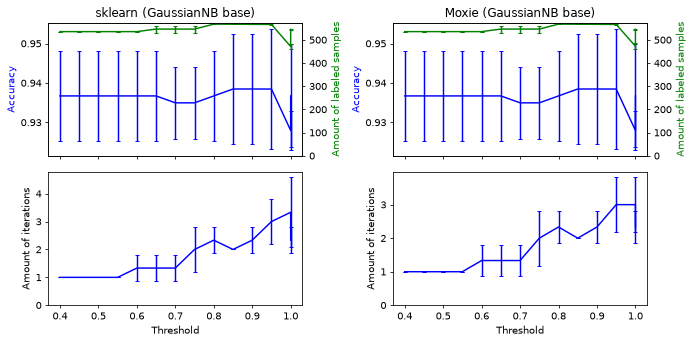

In [4]:
mx = nb.results["self_training_thresholds"]
mx_scores = np.empty_like(scores); mx_labeled = np.empty_like(amount_labeled); mx_iters = np.empty_like(amount_iterations)
k = 0
for i in range(len(x_values)):
    for fold, (train_index, test_index) in enumerate(folds):
        li = mx[f"labeled_iter_{i}_{fold}"]
        mx_labeled[i, fold] = total_samples - np.unique(li, return_counts=True)[1][0]
        mx_iters[i, fold] = np.max(li)
        mx_scores[i, fold] = accuracy_score(y_true[test_index], mx[f"pred_{i}_{fold}"])

fig, axes = plt.subplots(2, 2, figsize=(10, 5), dpi=70, sharex=True)
for col, (name, sc, lab, it) in enumerate([("sklearn", scores, amount_labeled, amount_iterations),
                                            ("Moxie", mx_scores, mx_labeled, mx_iters)]):
    ax1 = axes[0, col]
    ax1.errorbar(x_values, sc.mean(axis=1), yerr=sc.std(axis=1), capsize=2, color="b")
    ax1.set_ylabel("Accuracy", color="b"); ax1.set_title(name + " (GaussianNB base)")
    ax2 = ax1.twinx()
    ax2.errorbar(x_values, lab.mean(axis=1), yerr=lab.std(axis=1), capsize=2, color="g")
    ax2.set_ylim(bottom=0); ax2.set_ylabel("Amount of labeled samples", color="g")
    ax3 = axes[1, col]
    ax3.errorbar(x_values, it.mean(axis=1), yerr=it.std(axis=1), capsize=2, color="b")
    ax3.set_ylim(bottom=0); ax3.set_ylabel("Amount of iterations"); ax3.set_xlabel("Threshold")
plt.tight_layout(); plt.show()
moxie_nb.side_by_side(sklearn=scores, moxie=mx_scores)

In [5]:
nb.note("CalibratedClassifierCV(SVC) base estimator", "GAP",
        "no SVC CalibrationEstimator adapter (calibration PR #11 part 1) and no self-training adapter for "
        "CalibratedClassifierCV or other Moxie classifiers (semi_supervised tracking PR part 1); GaussianNB substituted")
# Threshold index 12 is 0.9999999999999999 (one ulp below 1). GaussianNB probabilities a few ulp below 1
# decide selection there; see the ADAPTED note. Every other threshold is compared exactly.
keep = [i for i in range(len(x_values)) if i != 12]
nb.compare("labeled_iter_ (13 thresholds x 3 folds)", np.concatenate([sk_labeled_iter[3 * i + f] for i in keep for f in range(3)]),
           np.concatenate([mx[f"labeled_iter_{i}_{f}"] for i in keep for f in range(3)]), exact=True)
nb.compare("n_iter_ (13 thresholds x 3 folds)", [sk_n_iter[3 * i + f] for i in keep for f in range(3)],
           [mx["n_iter"][3 * i + f] for i in keep for f in range(3)], exact=True)
ulp_rows = []
for f, (train_index, _) in enumerate(folds):
    Xt, yt = X[train_index], y[train_index]
    has = yt != -1
    p = GaussianNB().fit(Xt[has], yt[has]).predict_proba(Xt[~has]).max(axis=1)
    first = mx[f"labeled_iter_12_{f}"][np.nonzero(~has)[0]] == 1
    flipped = np.nonzero(first != (p > x_values[12]))[0]
    ulp_rows.append(((1 - p[flipped]) / np.spacing(x_values[12])).round(1).tolist())
print("first-iteration disagreements at threshold 0.9999999999999999, (1 - sklearn max_proba) in ulps:", ulp_rows)
nb.note("labeled_iter_/n_iter_ at threshold 0.9999999999999999", "ADAPTED",
        f"sklearn GaussianNB max_proba of the flipped samples is {ulp_rows} ulp (1.1e-16) below 1, i.e. below the threshold; "
        "Moxie GaussianNB.predict_log_proba rounds log-sum-exp to exactly jll_max there (scipy gives -8.9e-16), "
        "so the probability is 1.0 > threshold. A naive_bayes rounding difference within its 2e-9 parity bound, "
        "not a self-training defect; predictions and accuracy still agree exactly")
nb.compare("termination_condition_", np.array(sk_term), mx["termination"], exact=True)
nb.compare("predict(X_test)", np.concatenate(sk_pred),
           np.concatenate([mx[f"pred_{i}_{f}"] for i in range(len(x_values)) for f in range(3)]), exact=True)
nb.compare("accuracy per threshold and fold", scores, mx_scores, exact=True)
nb.compare("amount of labeled samples (13 thresholds)", amount_labeled[keep], mx_labeled[keep], exact=True)
nb.compare("last labeling iteration (13 thresholds)", amount_iterations[keep], mx_iters[keep], exact=True)
nb.compare("k_best samples labeled per iteration", np.concatenate([np.bincount(k[0] + 1) for k in kb]),
           np.concatenate([np.bincount(mx[f"kb_labeled_iter{f}"] + 1) for f in range(3)]), exact=True)
kb_diff = int(sum((k[0] != mx[f"kb_labeled_iter{f}"]).sum() for f, k in enumerate(kb)))
nb.note("k_best labeled_iter_ membership", "ADAPTED",
        f"{kb_diff} of 1138 samples are labeled in a different iteration: many unlabeled samples have probability exactly 1.0, "
        "so the top-10 set is tied; Moxie takes ties in input order, NumPy's argpartition (introselect) in an "
        "implementation-defined order (documented in docs/api-surface.md). Per-iteration counts and the final "
        "transduction_ agree exactly")
nb.compare("k_best transduction_", np.concatenate([k[3] for k in kb]),
           np.concatenate([mx[f"kb_transduction{f}"] for f in range(3)]), exact=True)
nb.compare("k_best n_iter_", [k[1] for k in kb], [mx[f"kb_n_iter{f}"][0] for f in range(3)], exact=True)
nb.compare("k_best termination_condition_", np.array([k[2] for k in kb]), mx["kb_termination"], exact=True)
nb.compare("k_best predict_proba(X_test)", np.vstack([k[4] for k in kb]), np.vstack([mx[f"kb_proba{f}"] for f in range(3)]),
           rtol=1e-6, atol=1e-9, reason="GaussianNB joint log-likelihoods of 30 features in Float64; exp of differing "
           "rounding in log-sum-exp; same tolerance class as the family GaussianNB parity (2e-9 absolute)")
nb.compare("k_best predict(X_test)", np.concatenate([k[5] for k in kb]), np.concatenate([mx[f"kb_pred{f}"] for f in range(3)]), exact=True)
nb.report()
nb.assert_parity()

first-iteration disagreements at threshold 0.9999999999999999, (1 - sklearn max_proba) in ulps: [[8.0, 32.0], [16.0, 16.0], [16.0]]


check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
CalibratedClassifierCV(SVC) base estimator,GAP,,,,,,no SVC CalibrationEstimator adapter (calibration PR #11 part 1) and no self-training adapter for CalibratedClassifierCV or other Moxie classifiers (semi_supervised tracking PR part 1); GaussianNB substituted,
labeled_iter_ (13 thresholds x 3 folds),PASS,"(14794,)","(14794,)",,,exact,0 mismatches,
n_iter_ (13 thresholds x 3 folds),PASS,"(39,)","(39,)",,,exact,0 mismatches,
labeled_iter_/n_iter_ at threshold 0.9999999999999999,ADAPTED,,,,,,"sklearn GaussianNB max_proba of the flipped samples is [[8.0, 32.0], [16.0, 16.0], [16.0]] ulp (1.1e-16) below 1, i.e. below the threshold; Moxie GaussianNB.predict_log_proba rounds log-sum-exp to exactly jll_max there (scipy gives -8.9e-16), so the probability is 1.0 > threshold. A naive_bayes rounding difference within its 2e-9 parity bound, not a self-training defect; predictions and accuracy still agree exactly",
termination_condition_,PASS,"(42,)","(42,)",,,exact,0 mismatches,
predict(X_test),PASS,"(7966,)","(7966,)",,,exact,0 mismatches,
accuracy per threshold and fold,PASS,"(14, 3)","(14, 3)",,,exact,0 mismatches,
amount of labeled samples (13 thresholds),PASS,"(13, 3)","(13, 3)",,,exact,0 mismatches,
last labeling iteration (13 thresholds),PASS,"(13, 3)","(13, 3)",,,exact,0 mismatches,
k_best samples labeled per iteration,PASS,"(111,)","(111,)",,,exact,0 mismatches,
